# Credit Card Fraud Detection: Shared Setup + E1 Baseline

**Both teammates run this notebook first.** It loads the data, checks it, makes the one shared stratified 80/20 split, defines the `evaluate()` function, and runs the E1 baseline. After this, Person A continues with E2/E3 and Person B with E4 to E6.

**Rules that keep your results comparable**
1. Same data file, same `RANDOM_STATE`, same split (saved to `split_seed42.npz`).
2. The test set is used **only** for final reporting. Tune with cross-validation on the training part.
3. Resampling happens **only inside the training data** (use a pipeline, see section 8).
4. Every result goes through `evaluate()` so the columns match.

**Setup (once):** `conda install -c conda-forge imbalanced-learn xgboost`, and put `creditcard.csv` (Kaggle: mlg-ulb/creditcardfraud) in the same folder as this notebook.

## 1. Imports and settings

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, KBinsDiscretizer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             fbeta_score, average_precision_score, roc_auc_score,
                             confusion_matrix, precision_recall_curve)

warnings.filterwarnings("ignore")

# ---- settings ----
DATA_PATH    = "creditcard.csv"
RANDOM_STATE = 42         
TEST_SIZE    = 0.20
SPLIT_FILE = "split_deduplicated_seed42.npz"
WHO          = "A"         # change to "B" on your teammate's copy
RUN_KNN      = False       # KNN on ~227K rows is slow; set True when you are ready to wait

## 2. Load the data and check it

In [2]:
df = pd.read_csv(DATA_PATH)
df = df.drop_duplicates().reset_index(drop=True)  
print("Shape:", df.shape)                      # expected: (284807, 31)
display(df.head())
print("\nClass counts:\n", df["Class"].value_counts())
print(f"Fraud rate: {df['Class'].mean()*100:.3f}%")        # expected: about 0.172%
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

Shape: (283726, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Class counts:
 Class
0    283253
1       473
Name: count, dtype: int64
Fraud rate: 0.167%
Missing values: 0
Duplicate rows: 0


## 3. Quick look at the data

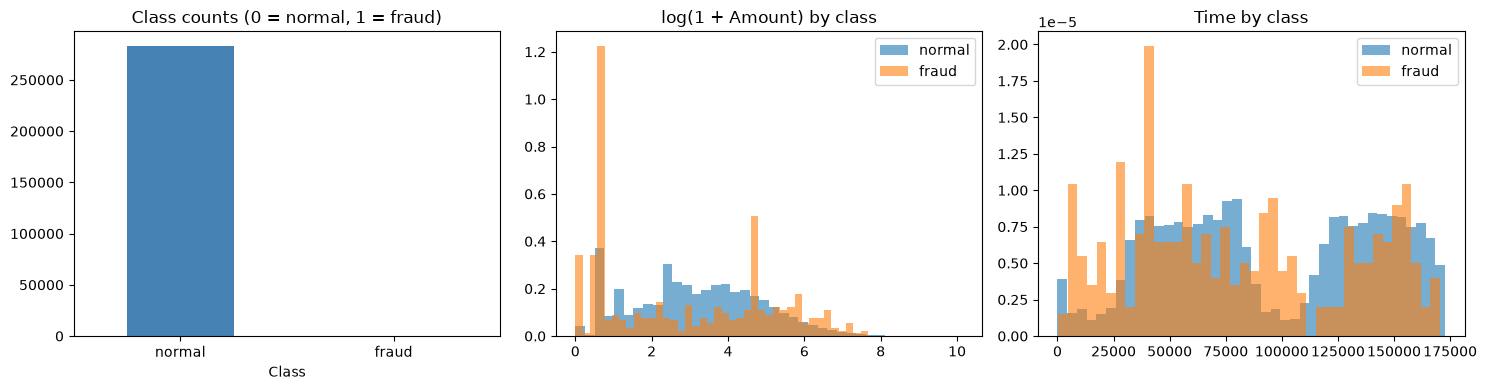

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,88.413575,250.379023,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.871860,260.211041,0.0,1.00,9.82,105.89,2125.87


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

df["Class"].value_counts().plot(kind="bar", ax=ax[0], color=["steelblue", "indianred"])
ax[0].set_title("Class counts (0 = normal, 1 = fraud)")
ax[0].set_xticklabels(["normal", "fraud"], rotation=0)

for c, name in [(0, "normal"), (1, "fraud")]:
    ax[1].hist(np.log1p(df.loc[df.Class == c, "Amount"]), bins=40, alpha=0.6, density=True, label=name)
ax[1].set_title("log(1 + Amount) by class"); ax[1].legend()

for c, name in [(0, "normal"), (1, "fraud")]:
    ax[2].hist(df.loc[df.Class == c, "Time"], bins=40, alpha=0.6, density=True, label=name)
ax[2].set_title("Time by class"); ax[2].legend()
plt.tight_layout(); plt.show()

display(df.groupby("Class")["Amount"].describe())

## 4. One shared stratified train/test split

The split is made once and the row indices are saved. If `split_seed42.npz` already exists it is reused, so both of you test on exactly the same rows. **Do not touch the test set until a model is final.**

In [4]:
X = df.drop(columns="Class")
y = df["Class"]

if os.path.exists(SPLIT_FILE):
    s = np.load(SPLIT_FILE)
    idx_train, idx_test = s["idx_train"], s["idx_test"]
    print("Loaded existing split from", SPLIT_FILE)
else:
    idx_train, idx_test = train_test_split(
        np.arange(len(df)), test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
    np.savez(SPLIT_FILE, idx_train=idx_train, idx_test=idx_test)
    print("Created and saved split to", SPLIT_FILE)

X_train, y_train = X.iloc[idx_train], y.iloc[idx_train]
X_test,  y_test  = X.iloc[idx_test],  y.iloc[idx_test]

print(f"Train: {len(X_train):,} rows, {int(y_train.sum())} frauds ({y_train.mean()*100:.3f}%)")
print(f"Test : {len(X_test):,} rows, {int(y_test.sum())} frauds ({y_test.mean()*100:.3f}%)")

Created and saved split to split_deduplicated_seed42.npz
Train: 226,980 rows, 378 frauds (0.167%)
Test : 56,746 rows, 95 frauds (0.167%)


## 5. Preprocessing helper

V1 to V28 are already PCA outputs on similar scales, so only `Time` and `Amount` are standardized. The scaler lives **inside the pipeline**, so it is fitted on training data only (no leakage). Naive Bayes gets its own binning step instead, because it needs categorical features.

In [5]:
def make_preprocessor():
    """Standardize Time and Amount, pass V1..V28 through unchanged."""
    return ColumnTransformer([("scale", StandardScaler(), ["Time", "Amount"])],
                             remainder="passthrough")

In [6]:
print(make_preprocessor())

ColumnTransformer(remainder='passthrough',
                  transformers=[('scale', StandardScaler(),
                                 ['Time', 'Amount'])])


## 6. The shared `evaluate()` function

Every experiment is reported through this function so that your result tables have identical columns. PR-AUC (`pr_auc`, average precision) is the main threshold-free score; its random baseline is the fraud rate (about 0.0017). `cost_10to1` is an **illustrative assumption** (a missed fraud costs 10 times a false alarm); change `FN_COST` / `FP_COST` if your report uses another ratio.

In [7]:
RESULTS = []
FN_COST, FP_COST = 10, 1     # assumed cost ratio for the threshold analysis (RP5)

def evaluate(exp, name, handling, model, X_te, y_te, threshold=0.5, store=True):
    """Score a FITTED model on (X_te, y_te). Returns a dict and stores it in RESULTS."""
    if hasattr(model, "predict_proba"):
        score = model.predict_proba(X_te)[:, 1]
        y_pred = (score >= threshold).astype(int)
    else:                                   # e.g. LinearSVC
        score = model.decision_function(X_te)
        y_pred = model.predict(X_te)

    tn, fp, fn, tp = confusion_matrix(y_te, y_pred, labels=[0, 1]).ravel()
    row = {
        "who": WHO, "exp": exp, "model": name, "handling": handling, "threshold": threshold,
        "accuracy":    accuracy_score(y_te, y_pred),
        "recall":      recall_score(y_te, y_pred, zero_division=0),
        "precision":   precision_score(y_te, y_pred, zero_division=0),
        "f1":          f1_score(y_te, y_pred, zero_division=0),
        "f2":          fbeta_score(y_te, y_pred, beta=2, zero_division=0),
        "pr_auc":      average_precision_score(y_te, score),
        "roc_auc":     roc_auc_score(y_te, score),
        "specificity": tn / (tn + fp),
        "fpr":         fp / (fp + tn),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "cost_10to1":  FN_COST * fn + FP_COST * fp,
    }
    if store:
        RESULTS.append(row)
    return row

def results_table():
    cols = ["who", "exp", "model", "handling", "accuracy", "recall", "precision",
            "f1", "f2", "pr_auc", "roc_auc", "TP", "FP", "FN", "TN", "cost_10to1"]
    return pd.DataFrame(RESULTS)[cols].round(4)

def save_results():
    results_table().to_csv(f"results_{WHO}.csv", index=False)
    print(f"Saved results_{WHO}.csv")

## 7. E1: baseline models on the untouched (imbalanced) training data

This answers **RP1**: how much does extreme imbalance hurt? Expect accuracy above 99.8% for every model, but weak fraud recall and a PR-AUC to compare with the fraud-rate baseline. The "always normal" dummy shows the accuracy trap.

In [8]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer
import warnings

# Show warnings instead of hiding potential problems.
warnings.resetwarnings()

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Reuse these exact folds for subsequent experiments.
CV_SPLITS = list(cv.split(X_train, y_train))

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "f2": make_scorer(fbeta_score, beta=2, zero_division=0),
    "average_precision": "average_precision",
    "roc_auc": "roc_auc",
}

baseline_models = {
    "Dummy (always normal)": Pipeline([
        ("clf", DummyClassifier(strategy="most_frequent"))
    ]),
    "Logistic regression": Pipeline([
        ("prep", make_preprocessor()),
        ("clf", LogisticRegression(max_iter=1000))
    ]),
    "Decision tree (depth 8)": Pipeline([
        ("clf", DecisionTreeClassifier(
            max_depth=8,
            random_state=RANDOM_STATE
        ))
    ]),
    "Naive Bayes (10 bins, alpha=1)": Pipeline([
        ("bin", KBinsDiscretizer(
            n_bins=10,
            encode="ordinal",
            strategy="quantile",
            random_state=RANDOM_STATE
        )),
        ("clf", CategoricalNB(alpha=1.0, min_categories=10))
    ]),
}

cv_rows = []

for name, model in baseline_models.items():
    print(f"Running: {name}", flush=True)

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=CV_SPLITS,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    for fold in range(5):
        row = {
            "experiment": "E1",
            "model": name,
            "handling": "none",
            "seed": RANDOM_STATE,
            "fold": fold + 1,
            "fit_seconds": scores["fit_time"][fold],
        }

        for metric in scoring:
            row[metric] = scores[f"test_{metric}"][fold]

        cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows)

cv_summary = (
    cv_results.groupby("model", sort=False)[list(scoring)]
    .agg(["mean", "std"])
)

display(cv_summary.round(4))

cv_results.to_csv("E1_cv_folds_deduplicated_seed42.csv", index=False)
cv_summary.to_csv("E1_cv_summary_deduplicated_seed42.csv")

print("Saved E1 cross-validation results.")

Running: Dummy (always normal)


/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL 

Running: Logistic regression


/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL 

Running: Decision tree (depth 8)


/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL 

Running: Naive Bayes (10 bins, alpha=1)


/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL 

accuracy         precision          recall  \
                                   mean     std      mean     std    mean   
model                                                                       
Dummy (always normal)            0.9983  0.0000    0.0000  0.0000  0.0000   
Logistic regression              0.9992  0.0001    0.8637  0.0285  0.6083   
Decision tree (depth 8)          0.9994  0.0001    0.8843  0.0407  0.7431   
Naive Bayes (10 bins, alpha=1)   0.9955  0.0007    0.2487  0.0246  0.8201   

                                            f1              f2          \
                                   std    mean     std    mean     std   
model                                                                    
Dummy (always normal)           0.0000  0.0000  0.0000  0.0000  0.0000   
Logistic regression             0.0605  0.7117  0.0354  0.6455  0.0524   
Decision tree (depth 8)         0.0565  0.8055  0.0239  0.7665  0.0440   
Naive Bayes (10 bins, alpha=1)  0.0577  0.3802  0.0231  0.5591  0.0166   

                               average_precision         roc_auc          
                                            mean     std    mean     std  
model                                                                     
Dummy (always normal)                     0.0017  0.0000  0.5000  0.0000  
Logistic regression                       0.7548  0.0345  0.9770  0.0160  
Decision tree (depth 8)                   0.6518  0.0351  0.8368  0.0364  
Naive Bayes (10 bins, alpha=1)            0.6479  0.0466  0.9651  0.0135

Saved E1 cross-validation results.


In [9]:
import sklearn
import joblib

print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)
print("Result rows:", len(cv_results))
print("Missing metric values:",
      cv_results[list(scoring)].isna().sum().sum())

scikit-learn: 1.9.1
joblib: 1.6.0
Result rows: 20
Missing metric values: 0


## 8. Template for the next experiments (resample inside a pipeline)

Resampling must only touch **training data**. With an `imblearn` pipeline the sampler runs on the training folds during `fit` and is skipped when predicting, so validation/test rows are never resampled. Use this pattern for E2/E3 (Person A) and as a starting point for E4 to E6 (Person B). The cell below tunes/validates with 5-fold CV on the **training set only**; use the test set only once, for the final chosen model.

In [10]:
from sklearn.base import clone
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

e2_rows = []

# sampling_strategy = minority count / majority count
ratios = {
    "1:1": 1.0,
    "1:10": 0.1
}

for ratio_name, strategy in ratios.items():
    for name, baseline in baseline_models.items():

        if name.startswith("Dummy"):
            continue

        # Preserve E1 preprocessing and classifier settings.
        steps = [
            (step_name, clone(step))
            for step_name, step in baseline.steps[:-1]
        ]

        steps += [
            ("rus", RandomUnderSampler(
                sampling_strategy=strategy,
                random_state=RANDOM_STATE
            )),
            ("clf", clone(baseline.steps[-1][1]))
        ]

        model = ImbPipeline(steps)

        print(f"Running E2: {name}, ratio {ratio_name}", flush=True)

        scores = cross_validate(
            model,
            X_train,
            y_train,
            cv=CV_SPLITS,
            scoring=scoring,
            n_jobs=1,
            error_score="raise"
        )

        for fold in range(len(CV_SPLITS)):
            row = {
                "experiment": "E2",
                "model": name,
                "handling": f"undersampling {ratio_name}",
                "seed": RANDOM_STATE,
                "fold": fold + 1,
                "fit_seconds": scores["fit_time"][fold],
            }

            for metric in scoring:
                row[metric] = scores[f"test_{metric}"][fold]

            e2_rows.append(row)

e2_results = pd.DataFrame(e2_rows)

e2_summary = (
    e2_results.groupby(["model", "handling"], sort=False)[list(scoring)]
    .agg(["mean", "std"])
)

display(e2_summary.round(4))

e2_results.to_csv(
    "E2_cv_folds_deduplicated_seed42.csv", index=False
)
e2_summary.to_csv(
    "E2_cv_summary_deduplicated_seed42.csv"
)

print("Result rows:", len(e2_results))
print("Missing metric values:",
      e2_results[list(scoring)].isna().sum().sum())
print("Saved E2 cross-validation results.")

Running E2: Logistic regression, ratio 1:1


/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL 

Running E2: Decision tree (depth 8), ratio 1:1


/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL 

Running E2: Naive Bayes (10 bins, alpha=1), ratio 1:1


/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL 

... (4 outputs left out)

Running E2: Naive Bayes (10 bins, alpha=1), ratio 1:10


/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL 

accuracy         precision  \
                                                      mean     std      mean   
model                          handling                                        
Logistic regression            undersampling 1:1    0.9658  0.0060    0.0436   
Decision tree (depth 8)        undersampling 1:1    0.9182  0.0202    0.0190   
Naive Bayes (10 bins, alpha=1) undersampling 1:1    0.9804  0.0015    0.0677   
Logistic regression            undersampling 1:10   0.9966  0.0007    0.3168   
Decision tree (depth 8)        undersampling 1:10   0.9923  0.0014    0.1638   
Naive Bayes (10 bins, alpha=1) undersampling 1:10   0.9881  0.0018    0.1081   

                                                           recall          \
                                                      std    mean     std   
model                          handling                                     
Logistic regression            undersampling 1:1   0.0065  0.9126  0.0276   
Decision tree (depth 8)        undersampling 1:1   0.0040  0.9099  0.0306   
Naive Bayes (10 bins, alpha=1) undersampling 1:1   0.0013  0.8439  0.0607   
Logistic regression            undersampling 1:10  0.0507  0.8703  0.0317   
Decision tree (depth 8)        undersampling 1:10  0.0263  0.8519  0.0438   
Naive Bayes (10 bins, alpha=1) undersampling 1:10  0.0103  0.8360  0.0681   

                                                       f1              f2  \
                                                     mean     std    mean   
model                          handling                                     
Logistic regression            undersampling 1:1   0.0832  0.0119  0.1826   
Decision tree (depth 8)        undersampling 1:1   0.0372  0.0076  0.0873   
Naive Bayes (10 bins, alpha=1) undersampling 1:1   0.1254  0.0020  0.2561   
Logistic regression            undersampling 1:10  0.4622  0.0522  0.6411   
Decision tree (depth 8)        undersampling 1:10  0.2740  0.0374  0.4606   
Naive Bayes (10 bins, alpha=1) undersampling 1:10  0.1910  0.0141  0.3544   

                                                          average_precision  \
                                                      std              mean   
model                          handling                                       
Logistic regression            undersampling 1:1   0.0231            0.6023   
Decision tree (depth 8)        undersampling 1:1   0.0168            0.0177   
Naive Bayes (10 bins, alpha=1) undersampling 1:1   0.0041            0.6621   
Logistic regression            undersampling 1:10  0.0393            0.7312   
Decision tree (depth 8)        undersampling 1:10  0.0447            0.1526   
Naive Bayes (10 bins, alpha=1) undersampling 1:10  0.0131            0.6510   

                                                          roc_auc          
                                                      std    mean     std  
model                          handling                                    
Logistic regression            undersampling 1:1   0.1299  0.9809  0.0087  
Decision tree (depth 8)        undersampling 1:1   0.0030  0.9145  0.0164  
Naive Bayes (10 bins, alpha=1) undersampling 1:1   0.0369  0.9651  0.0139  
Logistic regression            undersampling 1:10  0.0199  0.9826  0.0083  
Decision tree (depth 8)        undersampling 1:10  0.0417  0.9197  0.0497  
Naive Bayes (10 bins, alpha=1) undersampling 1:10  0.0432  0.9652  0.0136

Result rows: 30
Missing metric values: 0
Saved E2 cross-validation results.


In [11]:
from imblearn.over_sampling import RandomOverSampler

e3_rows = []

for name, baseline in baseline_models.items():
    if name.startswith("Dummy"):
        continue

    steps = [
        (step_name, clone(step))
        for step_name, step in baseline.steps[:-1]
    ]

    steps += [
        ("ros", RandomOverSampler(
            sampling_strategy=1.0,
            random_state=RANDOM_STATE
        )),
        ("clf", clone(baseline.steps[-1][1]))
    ]

    model = ImbPipeline(steps)

    print(f"Running E3: {name}, oversampling 1:1", flush=True)

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=CV_SPLITS,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    for fold in range(len(CV_SPLITS)):
        row = {
            "experiment": "E3",
            "model": name,
            "handling": "oversampling 1:1",
            "seed": RANDOM_STATE,
            "fold": fold + 1,
            "fit_seconds": scores["fit_time"][fold],
        }

        for metric in scoring:
            row[metric] = scores[f"test_{metric}"][fold]

        e3_rows.append(row)

e3_results = pd.DataFrame(e3_rows)

e3_summary = (
    e3_results.groupby(["model", "handling"], sort=False)[list(scoring)]
    .agg(["mean", "std"])
)

display(e3_summary.round(4))

e3_results.to_csv(
    "E3_cv_folds_deduplicated_seed42.csv", index=False
)
e3_summary.to_csv(
    "E3_cv_summary_deduplicated_seed42.csv"
)

print("Result rows:", len(e3_results))
print("Missing metric values:",
      e3_results[list(scoring)].isna().sum().sum())
print("Saved E3 cross-validation results.")

Running E3: Logistic regression, oversampling 1:1


/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL 

Running E3: Decision tree (depth 8), oversampling 1:1


/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL 

Running E3: Naive Bayes (10 bins, alpha=1), oversampling 1:1


/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL 

accuracy         precision  \
                                                    mean     std      mean   
model                          handling                                      
Logistic regression            oversampling 1:1   0.9760  0.0030    0.0607   
Decision tree (depth 8)        oversampling 1:1   0.9896  0.0045    0.1354   
Naive Bayes (10 bins, alpha=1) oversampling 1:1   0.9871  0.0019    0.1010   

                                                         recall          \
                                                    std    mean     std   
model                          handling                                   
Logistic regression            oversampling 1:1  0.0077  0.9153  0.0243   
Decision tree (depth 8)        oversampling 1:1  0.0548  0.8175  0.0570   
Naive Bayes (10 bins, alpha=1) oversampling 1:1  0.0098  0.8413  0.0658   

                                                     f1              f2  \
                                                   mean     std    mean   
model                          handling                                   
Logistic regression            oversampling 1:1  0.1138  0.0135  0.2393   
Decision tree (depth 8)        oversampling 1:1  0.2285  0.0789  0.3946   
Naive Bayes (10 bins, alpha=1) oversampling 1:1  0.1799  0.0144  0.3395   

                                                        average_precision  \
                                                    std              mean   
model                          handling                                     
Logistic regression            oversampling 1:1  0.0236            0.7538   
Decision tree (depth 8)        oversampling 1:1  0.0974            0.5099   
Naive Bayes (10 bins, alpha=1) oversampling 1:1  0.0175            0.6699   

                                                        roc_auc          
                                                    std    mean     std  
model                          handling                                  
Logistic regression            oversampling 1:1  0.0299  0.9814  0.0090  
Decision tree (depth 8)        oversampling 1:1  0.0681  0.9093  0.0241  
Naive Bayes (10 bins, alpha=1) oversampling 1:1  0.0421  0.9644  0.0130

Result rows: 15
Missing metric values: 0
Saved E3 cross-validation results.


In [12]:
knn_configs = [
    ("E1", "none", None),
    ("E2", "undersampling 1:1",
     RandomUnderSampler(
         sampling_strategy=1.0, random_state=RANDOM_STATE
     )),
    ("E2", "undersampling 1:10",
     RandomUnderSampler(
         sampling_strategy=0.1, random_state=RANDOM_STATE
     )),
    ("E3", "oversampling 1:1",
     RandomOverSampler(
         sampling_strategy=1.0, random_state=RANDOM_STATE
     )),
]

knn_rows = []

for experiment, handling, sampler in knn_configs:
    steps = [("prep", make_preprocessor())]

    if sampler is not None:
        steps.append(("sampler", clone(sampler)))

    steps.append(("clf", KNeighborsClassifier(
        n_neighbors=5,
        algorithm="brute",
        n_jobs=1
    )))

    model = ImbPipeline(steps)
    print(f"Running KNN: {experiment}, {handling}", flush=True)

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=CV_SPLITS,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    for fold in range(len(CV_SPLITS)):
        row = {
            "experiment": experiment,
            "model": "KNN (k=5)",
            "handling": handling,
            "seed": RANDOM_STATE,
            "fold": fold + 1,
            "fit_seconds": scores["fit_time"][fold],
            "score_seconds": scores["score_time"][fold],
        }

        for metric in scoring:
            row[metric] = scores[f"test_{metric}"][fold]

        knn_rows.append(row)

    # Save progress after each completed configuration.
    pd.DataFrame(knn_rows).to_csv(
        "KNN_cv_folds_deduplicated_seed42.csv", index=False
    )

knn_results = pd.DataFrame(knn_rows)

knn_summary = (
    knn_results.groupby(
        ["experiment", "model", "handling"], sort=False
    )[list(scoring)]
    .agg(["mean", "std"])
)

display(knn_summary.round(4))

knn_summary.to_csv("KNN_cv_summary_deduplicated_seed42.csv")

print("Result rows:", len(knn_results))
print("Missing metric values:",
      knn_results[list(scoring)].isna().sum().sum())
print("Saved KNN cross-validation results.")

Running KNN: E1, none


/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL 

Running KNN: E2, undersampling 1:1


/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL 

Running KNN: E2, undersampling 1:10


/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL 

Running KNN: E3, oversampling 1:1


/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL 

accuracy         precision          \
                                            mean     std      mean     std   
experiment model     handling                                                
E1         KNN (k=5) none                 0.9995  0.0002    0.9190  0.0561   
E2         KNN (k=5) undersampling 1:1    0.9781  0.0020    0.0636  0.0038   
                     undersampling 1:10   0.9978  0.0007    0.4397  0.0834   
E3         KNN (k=5) oversampling 1:1     0.9992  0.0001    0.7094  0.0260   

                                         recall              f1          \
                                           mean     std    mean     std   
experiment model     handling                                             
E1         KNN (k=5) none                0.7620  0.0851  0.8322  0.0707   
E2         KNN (k=5) undersampling 1:1   0.8836  0.0354  0.1187  0.0064   
                     undersampling 1:10  0.8519  0.0469  0.5754  0.0746   
E3         KNN (k=5) oversampling 1:1    0.8359  0.0500  0.7667  0.0250   

                                             f2         average_precision  \
                                           mean     std              mean   
experiment model     handling                                               
E1         KNN (k=5) none                0.7884  0.0797            0.7940   
E2         KNN (k=5) undersampling 1:1   0.2467  0.0096            0.2822   
                     undersampling 1:10  0.7115  0.0520            0.6321   
E3         KNN (k=5) oversampling 1:1    0.8065  0.0373            0.7265   

                                                roc_auc          
                                            std    mean     std  
experiment model     handling                                    
E1         KNN (k=5) none                0.0586  0.9218  0.0261  
E2         KNN (k=5) undersampling 1:1   0.0444  0.9688  0.0082  
                     undersampling 1:10  0.0893  0.9406  0.0104  
E3         KNN (k=5) oversampling 1:1    0.0437  0.9218  0.0261

Result rows: 20
Missing metric values: 0
Saved KNN cross-validation results.


In [13]:
all_a_results = pd.concat(
    [cv_results, e2_results, e3_results, knn_results],
    ignore_index=True
)

key_columns = ["experiment", "model", "handling", "seed", "fold"]

assert len(all_a_results) == 85, "Expected 85 fold results."
assert not all_a_results.duplicated(key_columns).any(), \
    "Duplicate experiment/fold entries found."
assert all_a_results[list(scoring)].notna().all().all(), \
    "Missing metric values found."

all_a_summary = (
    all_a_results.groupby(
        ["experiment", "model", "handling"], sort=False
    )[list(scoring)]
    .agg(["mean", "std"])
)

all_a_results.to_csv("Person_A_cv_folds_seed42.csv", index=False)
all_a_summary.to_csv("Person_A_cv_summary_seed42.csv")

ranking = (
    all_a_results.groupby(
        ["experiment", "model", "handling"]
    )[["average_precision", "precision", "recall", "f1", "f2"]]
    .mean()
    .sort_values("average_precision", ascending=False)
)

display(ranking.round(4))
print("Total fold results:", len(all_a_results))
print("Saved consolidated Person A results.")

average_precision  \
experiment model                          handling                                
E1         KNN (k=5)                      none                           0.7940   
           Logistic regression            none                           0.7548   
E3         Logistic regression            oversampling 1:1               0.7538   
E2         Logistic regression            undersampling 1:10             0.7312   
E3         KNN (k=5)                      oversampling 1:1               0.7265   
           Naive Bayes (10 bins, alpha=1) oversampling 1:1               0.6699   
E2         Naive Bayes (10 bins, alpha=1) undersampling 1:1              0.6621   
E1         Decision tree (depth 8)        none                           0.6518   
E2         Naive Bayes (10 bins, alpha=1) undersampling 1:10             0.6510   
E1         Naive Bayes (10 bins, alpha=1) none                           0.6479   
E2         KNN (k=5)                      undersampling 1:10             0.6321   
           Logistic regression            undersampling 1:1              0.6023   
E3         Decision tree (depth 8)        oversampling 1:1               0.5099   
E2         KNN (k=5)                      undersampling 1:1              0.2822   
           Decision tree (depth 8)        undersampling 1:10             0.1526   
                                          undersampling 1:1              0.0177   
E1         Dummy (always normal)          none                           0.0017   

                                                              precision  \
experiment model                          handling                        
E1         KNN (k=5)                      none                   0.9190   
           Logistic regression            none                   0.8637   
E3         Logistic regression            oversampling 1:1       0.0607   
E2         Logistic regression            undersampling 1:10     0.3168   
E3         KNN (k=5)                      oversampling 1:1       0.7094   
           Naive Bayes (10 bins, alpha=1) oversampling 1:1       0.1010   
E2         Naive Bayes (10 bins, alpha=1) undersampling 1:1      0.0677   
E1         Decision tree (depth 8)        none                   0.8843   
E2         Naive Bayes (10 bins, alpha=1) undersampling 1:10     0.1081   
E1         Naive Bayes (10 bins, alpha=1) none                   0.2487   
E2         KNN (k=5)                      undersampling 1:10     0.4397   
           Logistic regression            undersampling 1:1      0.0436   
E3         Decision tree (depth 8)        oversampling 1:1       0.1354   
E2         KNN (k=5)                      undersampling 1:1      0.0636   
           Decision tree (depth 8)        undersampling 1:10     0.1638   
                                          undersampling 1:1      0.0190   
E1         Dummy (always normal)          none                   0.0000   

                                                              recall      f1  \
experiment model                          handling                             
E1         KNN (k=5)                      none                0.7620  0.8322   
           Logistic regression            none                0.6083  0.7117   
E3         Logistic regression            oversampling 1:1    0.9153  0.1138   
E2         Logistic regression            undersampling 1:10  0.8703  0.4622   
E3         KNN (k=5)                      oversampling 1:1    0.8359  0.7667   
           Naive Bayes (10 bins, alpha=1) oversampling 1:1    0.8413  0.1799   
E2         Naive Bayes (10 bins, alpha=1) undersampling 1:1   0.8439  0.1254   
E1         Decision tree (depth 8)        none                0.7431  0.8055   
E2         Naive Bayes (10 bins, alpha=1) undersampling 1:10  0.8360  0.1910   
E1         Naive Bayes (10 bins, alpha=1) none                0.8201  0.3802   
E2         KNN (k=5)                      undersampling 1:10  0.8519  0.5754   
           Logisti

Total fold results: 85
Saved consolidated Person A results.


In [14]:
from sklearn.model_selection import GridSearchCV

lr_searches = {}
lr_tuning_rows = []

handling_options = [
    ("none", None),
    ("undersampling 1:1", RandomUnderSampler(
        sampling_strategy=1.0, random_state=RANDOM_STATE
    )),
    ("undersampling 1:10", RandomUnderSampler(
        sampling_strategy=0.1, random_state=RANDOM_STATE
    )),
    ("oversampling 1:1", RandomOverSampler(
        sampling_strategy=1.0, random_state=RANDOM_STATE
    )),
]

for handling, sampler in handling_options:
    steps = [("prep", make_preprocessor())]

    if sampler is not None:
        steps.append(("sampler", clone(sampler)))

    steps.append(("clf", LogisticRegression(max_iter=2000)))

    search = GridSearchCV(
        estimator=ImbPipeline(steps),
        param_grid={"clf__C": [0.01, 0.1, 1.0, 10.0]},
        scoring="average_precision",
        cv=CV_SPLITS,
        n_jobs=1,
        refit=True,
        error_score="raise"
    )

    print(f"Tuning logistic regression: {handling}", flush=True)
    search.fit(X_train, y_train)

    lr_searches[handling] = search

    candidate_results = pd.DataFrame(search.cv_results_)
    candidate_results["handling"] = handling
    lr_tuning_rows.append(candidate_results)

    print("Best C:", search.best_params_["clf__C"])
    print("Best CV average precision:",
          round(search.best_score_, 4))

lr_tuning_results = pd.concat(lr_tuning_rows, ignore_index=True)
lr_tuning_results.to_csv(
    "Person_A_LR_tuning_seed42.csv", index=False
)

display(
    lr_tuning_results[
        ["handling", "param_clf__C",
         "mean_test_score", "std_test_score", "rank_test_score"]
    ].round(4)
)

print("Saved logistic regression tuning results.")

Tuning logistic regression: none


/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL 

Best C: 1.0
Best CV average precision: 0.7548
Tuning logistic regression: undersampling 1:1


/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL 

Best C: 0.01
Best CV average precision: 0.6808
Tuning logistic regression: undersampling 1:10


/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL 

Best C: 10.0
Best CV average precision: 0.7352
Tuning logistic regression: oversampling 1:1


/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL 

Best C: 0.01
Best CV average precision: 0.7548


,handling,param_clf__C,mean_test_score,std_test_score,rank_test_score
0,none,0.01,0.7517,0.0278,4
1,none,0.10,0.7544,0.0295,2
2,none,1.00,0.7548,0.0309,1
3,none,10.00,0.7540,0.0312,3
4,undersampling 1:1,0.01,0.6808,0.0270,1
5,undersampling 1:1,0.10,0.6039,0.0341,3
6,undersampling 1:1,1.00,0.6023,0.1161,4
7,undersampling 1:1,10.00,0.6113,0.1480,2
8,undersampling 1:10,0.01,0.7233,0.0253,3
9,undersampling 1:10,0.10,0.7169,0.0187,4


Saved logistic regression tuning results.


In [15]:
tree_searches = {}
tree_tuning_rows = []

for handling, sampler in handling_options:
    steps = []

    if sampler is not None:
        steps.append(("sampler", clone(sampler)))

    steps.append(("clf", DecisionTreeClassifier(
        random_state=RANDOM_STATE
    )))

    search = GridSearchCV(
        estimator=ImbPipeline(steps),
        param_grid={"clf__max_depth": [3, 5, 8, 12]},
        scoring="average_precision",
        cv=CV_SPLITS,
        n_jobs=1,
        refit=True,
        error_score="raise"
    )

    print(f"Tuning decision tree: {handling}", flush=True)
    search.fit(X_train, y_train)

    tree_searches[handling] = search

    candidates = pd.DataFrame(search.cv_results_)
    candidates["handling"] = handling
    tree_tuning_rows.append(candidates)

    # Save progress after each handling strategy.
    pd.concat(tree_tuning_rows, ignore_index=True).to_csv(
        "Person_A_tree_tuning_seed42.csv", index=False
    )

    print("Best depth:", search.best_params_["clf__max_depth"])
    print("Best CV average precision:",
          round(search.best_score_, 4))

tree_tuning_results = pd.concat(
    tree_tuning_rows, ignore_index=True
)

display(
    tree_tuning_results[
        ["handling", "param_clf__max_depth",
         "mean_test_score", "std_test_score", "rank_test_score"]
    ].round(4)
)

print("Saved decision-tree tuning results.")

Tuning decision tree: none


/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL 

Best depth: 5
Best CV average precision: 0.746
Tuning decision tree: undersampling 1:1


/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL 

Best depth: 3
Best CV average precision: 0.0865
Tuning decision tree: undersampling 1:10


/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL 

Best depth: 3
Best CV average precision: 0.397
Tuning decision tree: oversampling 1:1


/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL PROJECT/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/mac/Desktop/FINAL 

Best depth: 12
Best CV average precision: 0.5269


,handling,param_clf__max_depth,mean_test_score,std_test_score,rank_test_score
0,none,3,0.6965,0.0347,2
1,none,5,0.7460,0.0387,1
2,none,8,0.6518,0.0314,3
3,none,12,0.6298,0.0368,4
4,undersampling 1:1,3,0.0865,0.0515,1
5,undersampling 1:1,5,0.0343,0.0053,2
6,undersampling 1:1,8,0.0177,0.0027,3
7,undersampling 1:1,12,0.0163,0.0017,4
8,undersampling 1:10,3,0.3970,0.0272,1
9,undersampling 1:10,5,0.2881,0.0483,2


Saved decision-tree tuning results.


In [ ]:
nb_searches = {}
nb_tuning_rows = []

for handling, sampler in handling_options:
    steps = [
        ("bin", KBinsDiscretizer(
            n_bins=10,
            encode="ordinal",
            strategy="quantile",
            random_state=RANDOM_STATE
        ))
    ]

    if sampler is not None:
        steps.append(("sampler", clone(sampler)))

    steps.append(("clf", CategoricalNB(min_categories=10)))

    search = GridSearchCV(
        estimator=ImbPipeline(steps),
        param_grid={"clf__alpha": [0.1, 0.5, 1.0, 5.0]},
        scoring="average_precision",
        cv=CV_SPLITS,
        n_jobs=1,
        refit=True,
        error_score="raise"
    )

    print(f"Tuning Naive Bayes: {handling}", flush=True)
    search.fit(X_train, y_train)

    nb_searches[handling] = search

    candidates = pd.DataFrame(search.cv_results_)
    candidates["handling"] = handling
    nb_tuning_rows.append(candidates)

    pd.concat(nb_tuning_rows, ignore_index=True).to_csv(
        "Person_A_NB_tuning_seed42.csv", index=False
    )

    print("Best alpha:", search.best_params_["clf__alpha"])
    print("Best CV average precision:",
          round(search.best_score_, 4))

nb_tuning_results = pd.concat(
    nb_tuning_rows, ignore_index=True
)

display(
    nb_tuning_results[
        ["handling", "param_clf__alpha",
         "mean_test_score", "std_test_score", "rank_test_score"]
    ].round(4)
)

print("Saved Naive Bayes tuning results.")

## 9. Who does what next

| | Person A | Person B |
|---|---|---|
| Experiments | E2 undersampling (1:1 and 1:10), E3 oversampling / SMOTE | E4 class weights, E5 random forest, balanced RF, AdaBoost, XGBoost, E6 stacking |
| Save results to | `results_A.csv` | `results_B.csv` |

Together at the end: E7 (feature selection and threshold choice on the best model), merge the two CSVs into one table, make the final PR curves, and write the conclusion and limitations.